# Saudi Specialty Coffee Beans — EDA and Data Cleaning

In this notebook I explore the Saudi specialty coffee dataset and prepare it for modeling. My goals are:

1. Fill the missing **bag sizes** and **origins** using clues inside the dataset.
2. Look deeply for any other problems in the data and fix them.
3. Make everything **unified**: the same value written the same way, and all text in **English**.
4. Fill **all** the missing values, so the final dataset is ready for modeling.

## 1. Import Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the Dataset

In [ ]:
df = pd.read_csv("../data/saudi_specialty_coffee_beans.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 569
Columns: 54


,bean_id,roaster,roaster_city,data_source,source_domain,coffee_name,product_type,is_infused,is_spiced,origin_country,...,other_attributes,price_original,currency,price_sar,weight_raw,weight_g,price_per_100g_sar,sizes_prices,collected_date,product_url
0,1,12 Cups Coffee,Riyadh,Qavashop marketplace,qavashop.com,12 Cups Colombia Excelso 250g,single_origin,0,0,Colombia,...,espresso and drip,46.00,SAR,46.00,250g,250.0,18.40,250g: 46.00; 1kg: 143.75,2026-11-09,https://qavashop.com/en/coffee/filter/Colombia...
1,2,12 Cups Coffee,Riyadh,Qavashop marketplace,qavashop.com,12 Cups Colombia Huila 250g,single_origin,0,0,Colombia,...,pour-over and espresso,81.43,SAR,81.43,250g,250.0,32.57,250g: 81.43; 1kg: 300.08,2026-11-09,https://qavashop.com/en/coffee/filter/Specialt...
2,3,12 Cups Coffee,Riyadh,Qavashop marketplace,qavashop.com,12 Cups Colombia San Adolfo 250g,single_origin,0,0,Colombia,...,out of stock,87.40,SAR,87.40,250g,250.0,34.96,NaN,2026-11-09,https://qavashop.com/en/coffee/filter/Colombia...
3,4,12 Cups Coffee,Riyadh,Qavashop marketplace,qavashop.com,12 Cups El Salvador Marcelo 250g,single_origin,0,0,El Salvador,...,pour-over and espresso; out of stock,69.00,SAR,69.00,250 g,250.0,27.60,250g: 69.00; 1kg: 238.05,2026-11-09,https://qavashop.com/en/coffee/filter/Specialt...
4,5,12 Cups Coffee,Riyadh,Qavashop marketplace,qavashop.com,12 Cups Ethiopia Guji Natural 1kg,single_origin,0,0,Ethiopia,...,NaN,161.00,SAR,161.00,1 kg,1000.0,16.10,NaN,2026-11-09,https://qavashop.com/en/coffee/filter/Coffee-B...


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 54 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   bean_id                  569 non-null    int64  
 1   roaster                  569 non-null    str    
 2   roaster_city             476 non-null    str    
 3   data_source              569 non-null    str    
 4   source_domain            569 non-null    str    
 5   coffee_name              569 non-null    str    
 6   product_type             569 non-null    str    
 7   is_infused               569 non-null    int64  
 8   is_spiced                569 non-null    int64  
 9   origin_country           524 non-null    str    
 10  origin_continent         524 non-null    str    
 11  origin_country_raw       524 non-null    str    
 12  country_taken_from_name  569 non-null    int64  
 13  region                   316 non-null    str    
 14  farm                     95 non-null 

## 3. Basic Statistics

In [ ]:
df[["price_sar", "weight_g", "price_per_100g_sar", "altitude_mean_m"]].describe()

,price_sar,weight_g,price_per_100g_sar,altitude_mean_m
count,420.000000,501.000000,374.000000,362.000000
mean,69.747095,291.145709,26.300508,1785.154696
std,44.259855,197.507622,13.551202,320.228205
min,20.240000,100.000000,8.100000,950.000000
25%,48.300000,250.000000,19.200000,1600.000000
50%,59.800000,250.000000,23.600000,1850.000000
75%,71.000000,250.000000,28.000000,2000.000000
max,448.500000,1000.000000,118.740000,2775.000000


In [ ]:
print("Number of roasters:", df["roaster"].nunique())
print()
print(df["product_type"].value_counts())

Number of roasters: 71

product_type
single_origin    486
blend             55
saudi_coffee      17
decaf             11
Name: count, dtype: int64


## 4. Duplicates

In [ ]:
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated coffees (same link and name):", df.duplicated(["product_url", "coffee_name"]).sum())

Duplicated rows: 0
Duplicated coffees (same link and name): 0


There are no duplicates, so I don't need to remove anything.

## 5. Missing Values

In [ ]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values()

total_missing_before = df.isna().sum().sum()
print("Total missing values:", total_missing_before)
print()
print(missing)

Total missing values: 8672

note_caramel_sweet     42
note_nutty             42
note_chocolate         42
note_floral            42
note_citrus            42
note_fruity            42
note_tea               42
note_spice             42
n_tasting_notes        42
tasting_notes          42
origin_country         45
origin_continent       45
origin_country_raw     45
process                55
process_raw            55
weight_raw             68
weight_g               68
other_attributes       84
roaster_city           93
price_original        149
currency              149
price_sar             149
price_per_100g_sar    195
altitude_raw          207
altitude_mean_m       207
altitude_min_m        207
altitude_max_m        207
suits_espresso        246
variety               249
region                253
suits_filter          258
body                  393
body_level            397
sizes_prices          429
roast_level           444
roast_level_raw       444
farm                  474
acidity   

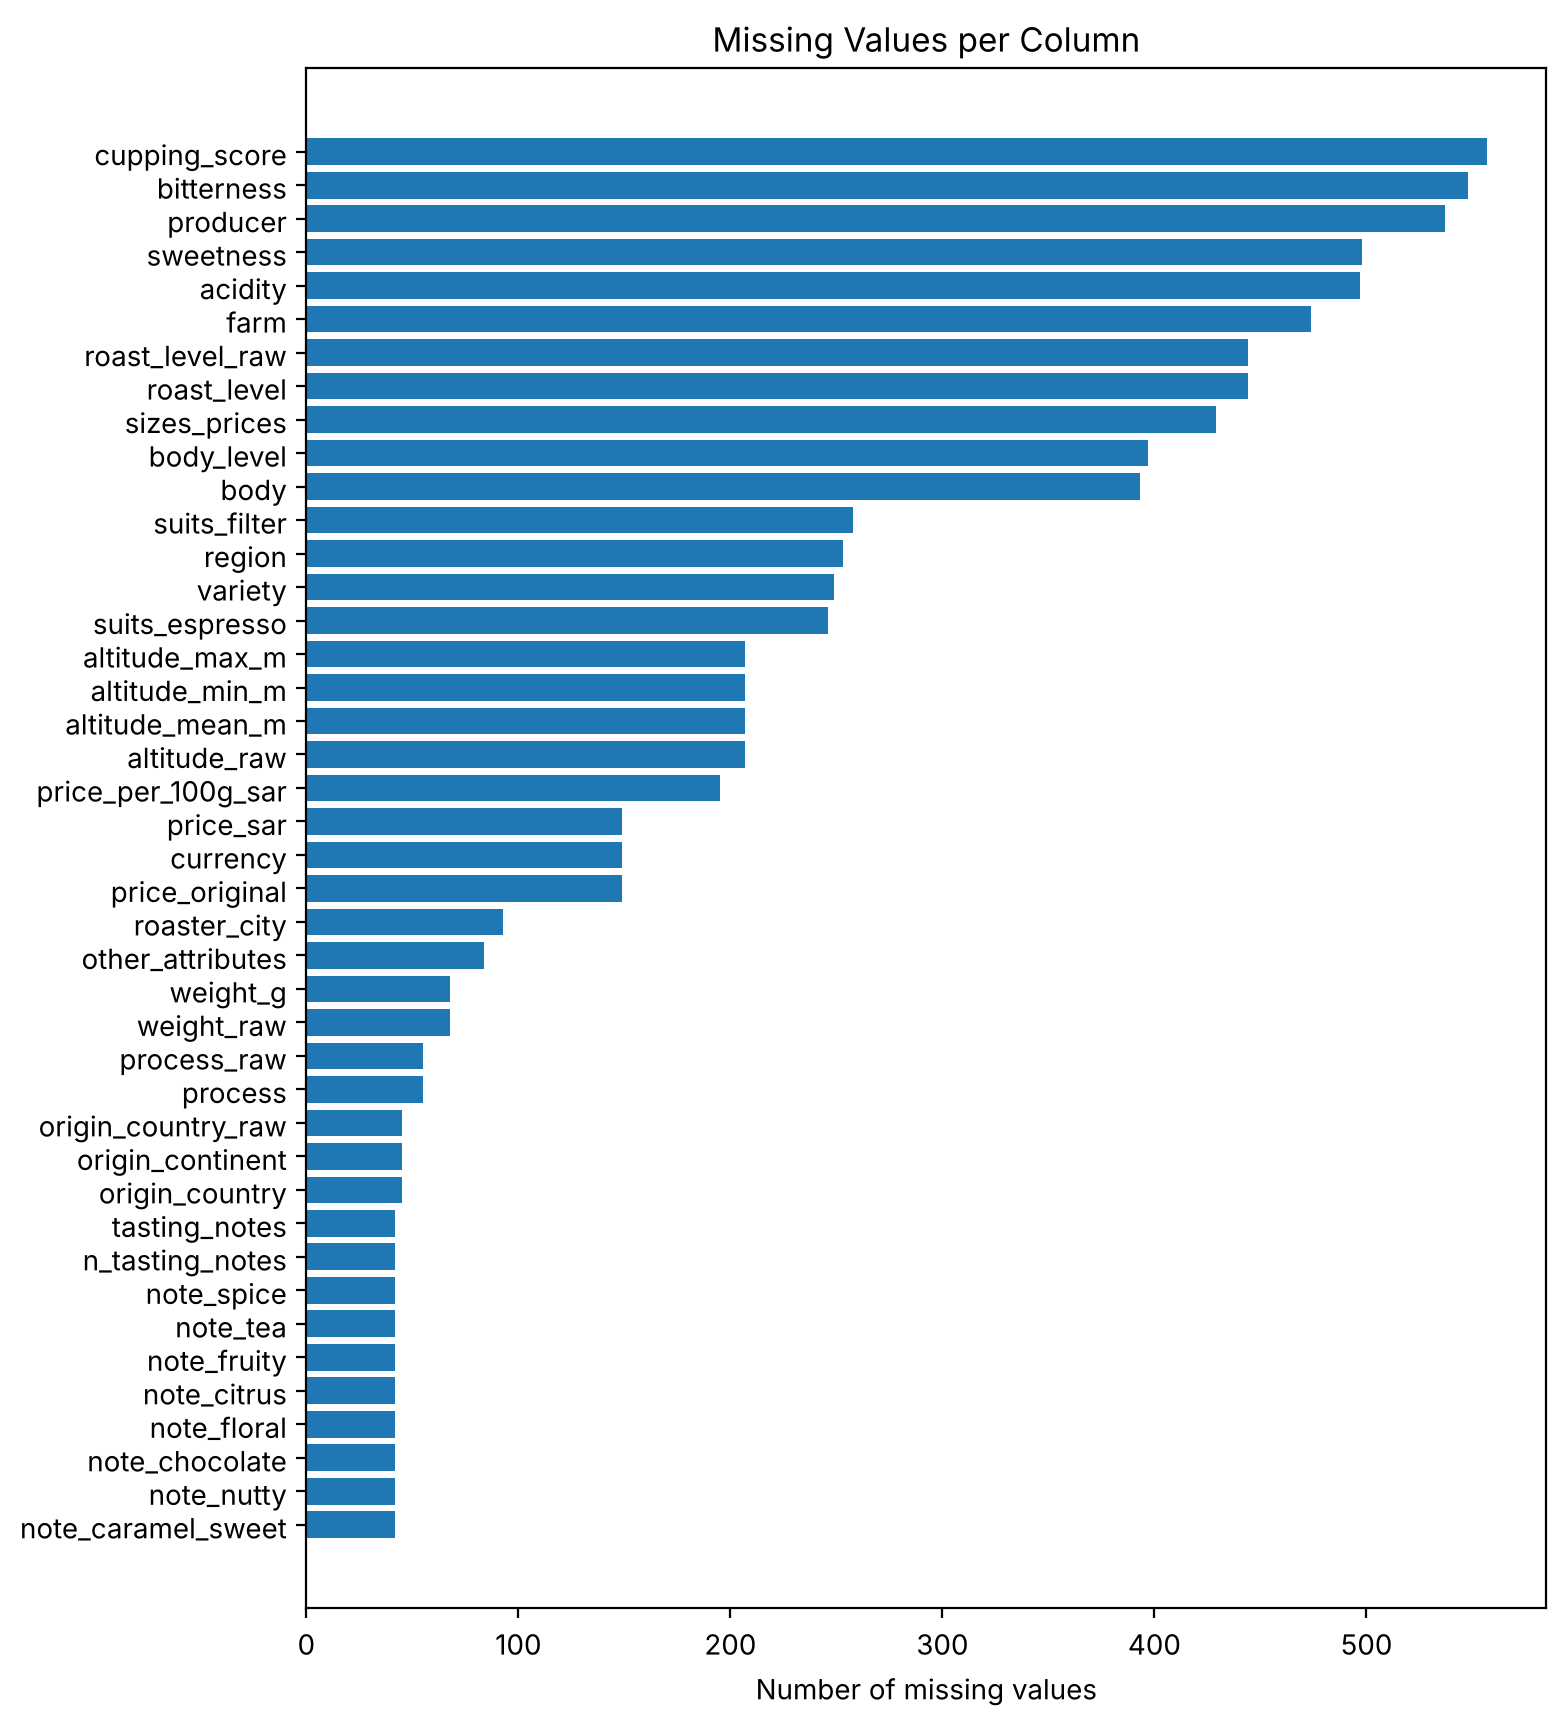

In [ ]:
plt.figure(figsize=(8, 10))
plt.barh(missing.index, missing.values)
plt.xlabel("Number of missing values")
plt.title("Missing Values per Column")
plt.show()

Many columns have missing values because most roasters don't publish everything (for example roast level or bitterness). I start with the two most important ones, the **bag size** and the **origin**, and then I handle all the others.

## 6. Filling the Missing Bag Sizes (`weight_g`)

In [ ]:
print("Missing sizes:", df["weight_g"].isna().sum())
print("Missing sizes that have a price:", (df["weight_g"].isna() & df["price_sar"].notna()).sum())
print()
print(df["weight_g"].value_counts())

Missing sizes: 68
Missing sizes that have a price: 46

weight_g
250.0     376
1000.0     33
125.0      24
227.0      21
200.0      13
100.0      12
500.0       9
175.0       6
150.0       4
120.0       2
907.0       1
Name: count, dtype: int64


Most coffees are sold in 250 g bags, and the second most common size is 1 kg. Let's look at the typical price for each size, using the rows where we know both.

In [ ]:
for size in [125, 200, 227, 250, 500, 1000]:
    prices = df.loc[df["weight_g"] == size, "price_sar"].dropna()
    print(size, "g -> median price:", round(prices.median(), 2), "SAR (", len(prices), "coffees )")

125 g -> median price: 59.0 SAR ( 9 coffees )
200 g -> median price: 58.5 SAR ( 10 coffees )
227 g -> median price: 54.5 SAR ( 20 coffees )
250 g -> median price: 57.36 SAR ( 289 coffees )
500 g -> median price: 95.0 SAR ( 7 coffees )
1000 g -> median price: 175.05 SAR ( 22 coffees )


A 250 g bag usually costs around 57 SAR and a 1 kg bag around 175 SAR, so the price clearly tells us if a bag is small or 1 kg. To find where to draw the line between them, I tried different price limits on the coffees where I already know the size, and counted how many the rule guessed correctly.

In [ ]:
known = df[df["weight_g"].isin([250, 1000]) & df["price_sar"].notna()]

for limit in [100, 110, 120, 130, 140, 150, 160]:
    correct = 0
    for i in known.index:
        if known.loc[i, "price_sar"] >= limit:
            guess = 1000
        else:
            guess = 250
        if guess == known.loc[i, "weight_g"]:
            correct = correct + 1
    print("limit", limit, "SAR ->", correct, "correct out of", len(known))

limit 100 SAR -> 298 correct out of 311
limit 110 SAR -> 300 correct out of 311
limit 120 SAR -> 305 correct out of 311
limit 130 SAR -> 307 correct out of 311
limit 140 SAR -> 305 correct out of 311
limit 150 SAR -> 304 correct out of 311
limit 160 SAR -> 304 correct out of 311


**130 SAR** gives the best result (307 out of 311 correct). So a coffee that costs 130 SAR or more is most likely a 1 kg bag.

When I looked deeper, I noticed that not every roaster uses 250 g for its small bag. For example, Roasting House sells 227 g bags and Olala sells 125 g bags. So for the small bags, I use the size that each roaster usually sells.

In [ ]:
usual_size = {}

for roaster in df["roaster"].unique():
    sizes = df.loc[(df["roaster"] == roaster) & (df["weight_g"] < 900), "weight_g"]
    if len(sizes) > 0:
        usual_size[roaster] = sizes.value_counts().index[0]
    else:
        usual_size[roaster] = 250

print("Roasting House:", usual_size["Roasting House"])
print("Olala Roastery:", usual_size["Olala Roastery"])
print("Kawn Roastery:", usual_size["Kawn Roastery"], "(no known sizes, so I used 250)")

Roasting House: 227.0
Olala Roastery: 125.0
Kawn Roastery: 250 (no known sizes, so I used 250)


So my final rule is:
- If the price is **130 SAR or more** → 1000 g
- If the price is **less than 130 SAR** → the roaster's usual small bag
- If there is **no price** → the roaster's usual small bag (250 g if the roaster has none)

In [ ]:
def guess_size(roaster, price):
    if pd.isna(price):
        return usual_size[roaster]
    if price >= 130:
        return 1000
    return usual_size[roaster]

Before using it, I tested the rule on all the coffees where I already know the size and the price:

In [ ]:
known = df[df["weight_g"].notna() & df["price_sar"].notna()]

correct = 0
for i in known.index:
    if guess_size(known.loc[i, "roaster"], known.loc[i, "price_sar"]) == known.loc[i, "weight_g"]:
        correct = correct + 1

print(correct, "correct out of", len(known), "=", round(correct / len(known) * 100, 1), "%")

331 correct out of 374 = 88.5 %


The rule guessed **88.5%** of the known sizes correctly. Most of its mistakes are roasters that sell more than one small size (for example 100 g and 250 g at similar prices). This is good enough, so I use it to fill the missing sizes.

In [ ]:
filled_from_price = 0
filled_no_price = 0

for i in df.index:
    if pd.isna(df.loc[i, "weight_g"]):
        df.loc[i, "weight_g"] = guess_size(df.loc[i, "roaster"], df.loc[i, "price_sar"])
        if pd.isna(df.loc[i, "price_sar"]):
            filled_no_price = filled_no_price + 1
        else:
            filled_from_price = filled_from_price + 1

print("Filled using the price:", filled_from_price)
print("Filled without a price (roaster's usual size):", filled_no_price)
print("Missing sizes now:", df["weight_g"].isna().sum())

Filled using the price: 46
Filled without a price (roaster's usual size): 22
Missing sizes now: 0


Now that every coffee has a size, I can calculate the **price per 100 g** for the coffees that have a price but were missing it.

In [ ]:
for i in df.index:
    if pd.isna(df.loc[i, "price_per_100g_sar"]) and pd.notna(df.loc[i, "price_sar"]):
        df.loc[i, "price_per_100g_sar"] = round(df.loc[i, "price_sar"] / df.loc[i, "weight_g"] * 100, 2)

print("Missing price per 100 g now:", df["price_per_100g_sar"].isna().sum())

Missing price per 100 g now: 149


The ones still missing are coffees with no price at all. I fill them later in section 15.

## 7. Filling the Missing Origin (`origin_country`)

In [ ]:
print("Missing origin countries:", df["origin_country"].isna().sum())
print()
print(df.loc[df["origin_country"].isna(), "product_type"].value_counts())

Missing origin countries: 45

product_type
blend            33
saudi_coffee      7
single_origin     4
decaf             1
Name: count, dtype: int64


Most of the coffees with no origin are **blends**, which mix beans from several countries, so they don't have one origin. Let's look at the rows that are not blends:

In [ ]:
no_origin = df[df["origin_country"].isna() & (df["product_type"] != "blend")]
no_origin[["roaster", "coffee_name", "product_type", "region", "other_attributes"]]

,roaster,coffee_name,product_type,region,other_attributes
127,Bunista,Bunista Saudi Roast 250g,saudi_coffee,NaN,100% Arabica; traditional brewing; roasted weekly
202,Elixir Bunn,إيمبارا,single_origin,NaN,مدرج في صفحة محاصيل القهوة بالموقع
206,Elixir Bunn,قهوة سعودية - مزيج المنطقة الجنوبية,saudi_coffee,NaN,قهوة سعودية منكهة بالهيل، القرنفل، الزعفران، ا...
207,Elixir Bunn,قهوة سعودية - مزيج المنطقة الشرقية,saudi_coffee,NaN,قهوة سعودية منكهة بالهيل والزعفران
208,Elixir Bunn,قهوة سعودية - مزيج المنطقة الشمالية,saudi_coffee,NaN,قهوة سعودية منكهة بالهيل، الزعفران والقرنفل؛ و...
209,Elixir Bunn,قهوة سعودية - مزيج المنطقة الغربية,saudi_coffee,NaN,قهوة سعودية منكهة بالهيل، القرنفل، الزعفران وا...
210,Elixir Bunn,قهوة سعودية - مزيج المنطقة الوسطى,saudi_coffee,NaN,قهوة سعودية منكهة بالهيل، الزعفران والقرنفل
214,Elixir Bunn,كيفو,single_origin,NaN,مدرج في صفحة محاصيل القهوة بالموقع
257,Hjeen,برالين,single_origin,NaN,توازن مثالي؛ من أحدث محاصيل هجين؛ للاسبريسو وا...
526,TRUTH Roastery,Fahmi Faysel Abdosh,single_origin,NaN,name and sizes only: the official store loads ...


What I found by looking at each row:

- The 5 Elixir Bunn Saudi coffees have **"مزيج"** (blend) in their name, so they are blends too.
- The dr.CAFE decaf says **"decaf blend"** in the other attributes.
- **"Fahmi Faysel Abdosh"** from TRUTH: Faysel Abdosh is an Ethiopian coffee producer, and the dataset already has another TRUTH coffee called "Ethiopia Faysel Abdosh Keramo", so this one is from **Ethiopia**.
- The rest (Bunista Saudi Roast, the Coffee Factory Arabic coffee, إيمبارا, كيفو and برالين) give no clue about the country. Kivu is a lake between Rwanda and DR Congo, so I can't choose one. I label these as **Unknown** instead of guessing.

So my rule is:
- Blend (in the product type, the name or the other attributes) → **Multiple**
- Name has "Abdosh" → **Ethiopia**
- Anything else → **Unknown**

In [ ]:
for i in df.index:
    if pd.isna(df.loc[i, "origin_country"]):
        name = str(df.loc[i, "coffee_name"]).lower()
        other = str(df.loc[i, "other_attributes"]).lower()

        if df.loc[i, "product_type"] == "blend" or "مزيج" in name or "blend" in name or "blend" in other:
            df.loc[i, "origin_country"] = "Multiple"
        elif "abdosh" in name:
            df.loc[i, "origin_country"] = "Ethiopia"
        else:
            df.loc[i, "origin_country"] = "Unknown"

print(df.loc[no_origin.index, ["coffee_name", "origin_country"]])
print()
print("Missing origin countries now:", df["origin_country"].isna().sum())

                                 coffee_name origin_country
127                 Bunista Saudi Roast 250g        Unknown
202                                  إيمبارا        Unknown
206      قهوة سعودية - مزيج المنطقة الجنوبية       Multiple
207       قهوة سعودية - مزيج المنطقة الشرقية       Multiple
208      قهوة سعودية - مزيج المنطقة الشمالية       Multiple
209       قهوة سعودية - مزيج المنطقة الغربية       Multiple
210        قهوة سعودية - مزيج المنطقة الوسطى       Multiple
214                                     كيفو        Unknown
257                                   برالين        Unknown
526                      Fahmi Faysel Abdosh       Ethiopia
533  قهوة عربية - مصنع القهوة | Arabic Saudi        Unknown
560              dr.CAFE Decaf Espresso 250g       Multiple

Missing origin countries now: 0


## 8. Filling the Missing Continent (`origin_continent`)

The dataset already tells us which continent each country belongs to, so I build that list from the rows that have both.

In [ ]:
continent_of = {}

for i in df.index:
    country = df.loc[i, "origin_country"]
    continent = df.loc[i, "origin_continent"]
    if pd.notna(continent):
        continent_of[country] = continent

continent_of["Unknown"] = "Unknown"

print(continent_of)

{'Colombia': 'Latin America', 'El Salvador': 'Latin America', 'Ethiopia': 'Africa', 'Peru': 'Latin America', 'Guatemala': 'Latin America', 'Brazil': 'Latin America', 'Costa Rica': 'Latin America', 'Uganda': 'Africa', 'Multiple': 'Multiple', 'Yemen': 'Arabian Peninsula', 'Indonesia': 'Asia', 'Panama': 'Latin America', 'Saudi Arabia': 'Arabian Peninsula', 'China': 'Asia', 'Nicaragua': 'Latin America', 'India': 'Asia', 'Brazil; Colombia': 'Multiple', 'Honduras': 'Latin America', 'Rwanda': 'Africa', 'Kenya': 'Africa', 'Costa Rica; Honduras; Ethiopia': 'Multiple', 'Colombia; Brazil; Ethiopia': 'Multiple', 'Ethiopia; Brazil': 'Multiple', 'Brazil; Ethiopia': 'Multiple', 'Brazil; Uganda': 'Multiple', 'Indonesia; Yemen': 'Multiple', 'Ecuador': 'Latin America', 'Brazil; Honduras; Ethiopia': 'Multiple', 'Myanmar': 'Asia', 'Indonesia; Guatemala; Ethiopia': 'Multiple', 'Papua New Guinea': 'Oceania', 'Unknown': 'Unknown'}


Some blends say where their beans come from in the `region` column. For example, two dr.CAFE blends and the Medd "فريدا" blend say "Latin America" or "South America", so their continent is Latin America instead of Multiple.

In [ ]:
for i in df.index:
    if pd.isna(df.loc[i, "origin_continent"]):
        country = df.loc[i, "origin_country"]
        region = str(df.loc[i, "region"])

        if country == "Multiple" and ("Latin America" in region or "South America" in region) and "Africa" not in region:
            df.loc[i, "origin_continent"] = "Latin America"
        else:
            df.loc[i, "origin_continent"] = continent_of[country]

print(df["origin_continent"].value_counts())
print()
print("Missing continents now:", df["origin_continent"].isna().sum())

origin_continent
Latin America        281
Africa               173
Multiple              57
Arabian Peninsula     29
Asia                  23
Unknown                5
Oceania                1
Name: count, dtype: int64

Missing continents now: 0


## 9. Filling the Missing Region from the Coffee Name

Some coffee names include the region, like **"Ethiopia Guji"** or **"إثيوبيا هامبيلا"**, but the `region` column is empty for them. I made a list of famous coffee regions (in English and Arabic) and searched the names of the single-origin coffees for them.

In [ ]:
regions = {
    "guji": "Guji", "قوجي": "Guji",
    "hambela": "Hambela", "هامبيلا": "Hambela", "همبيلا": "Hambela",
    "yirga": "Yirgacheffe", "يرقاتشيف": "Yirgacheffe",
    "sidam": "Sidamo", "سيدامو": "Sidamo", "keramo": "Sidamo",
    "gedeb": "Gedeb", "gideb": "Gedeb", "قيدب": "Gedeb",
    "chelchele": "Chelchele", "شلشلي": "Chelchele", "شيلشي": "Chelchele",
    "huila": "Huila", "ويلا": "Huila", "neiva": "Huila",
    "antioquia": "Antioquia", "انتيوكيا": "Antioquia",
    "tolima": "Tolima", "cauca": "Cauca",
    "minas": "Minas Gerais", "cerrado": "Cerrado", "mogiana": "Mogiana",
    "haraz": "Haraz", "حراز": "Haraz",
    "tarrazu": "Tarrazu", "antigua": "Antigua",
    "kintamani": "Kintamani", "yunnan": "Yunnan", "lao xu zhai": "Yunnan",
}

for i in df.index:
    if pd.isna(df.loc[i, "region"]) and df.loc[i, "product_type"] != "blend":
        name = str(df.loc[i, "coffee_name"]).lower()
        for word in regions:
            if word in name:
                df.loc[i, "region"] = regions[word]
                print(df.loc[i, "coffee_name"], "->", regions[word])
                break

إثيوبيا شيلشي 250g -> Chelchele
إثيوبيا هامبيلا 250g -> Hambela
Bunista China Lao Xu Zhai 1 Kg -> Yunnan
Colombia Neiva -> Huila
Ethiopia Faysel Abdosh Keramo Rank 1 -> Sidamo
Ethiopia Gideb -> Gedeb
Ethiopia Guji -> Guji


I found 7 regions. Two of them needed a little more knowledge: **Neiva** is the capital of Huila in Colombia, and **Keramo** is in the Sidamo area of Ethiopia. **Lao Xu Zhai** is in Yunnan, which the dataset already shows for another Chinese coffee.

The other coffees with no region don't mention it anywhere (their names are lot names or flavors like "Passion Fruit").

## 10. A Deeper Look for Other Problems

Before modeling, I checked the whole dataset for anything else that needs fixing.

### 10.1 Mixed languages

In [ ]:
def has_arabic(text):
    for letter in str(text):
        if "\u0600" <= letter <= "\u06FF":
            return True
    return False

print("Rows with Arabic text in each column:")
for col in df.columns:
    count = 0
    for value in df[col]:
        if pd.notna(value) and has_arabic(value):
            count = count + 1
    if count > 0:
        print(" ", col, ":", count)

Rows with Arabic text in each column:
  coffee_name : 369
  origin_country_raw : 174
  region : 116
  farm : 27
  producer : 17
  variety : 211
  process_raw : 328
  altitude_raw : 232
  roast_level_raw : 35
  tasting_notes : 339
  body : 104
  acidity : 36
  sweetness : 30
  other_attributes : 69
  weight_raw : 128


Many columns mix Arabic and English, so the same thing can appear in two languages. I translate everything to English in section 13.

### 10.2 The same value written in different ways

In [ ]:
print(df["weight_raw"].value_counts().head(12))

weight_raw
250g        225
250 جرام     65
250 g        61
227 جرام     19
125g         15
1kg           8
250 جم        8
250G          8
100 جرام      8
1000g         7
200 g         6
175 g         6
Name: count, dtype: int64


In [ ]:
for size in [250, 1000]:
    writings = df.loc[df["weight_g"] == size, "weight_raw"].dropna().unique()
    print(size, "g is written in", len(writings), "different ways:", list(writings))

250 g is written in 12 different ways: ['250g', '250 g', '250 جرام', '250 جم', '250ج', '250 غرام', '0.25 KG', '250G', '250جم', '250غ', '0.25 kg', '250جرام']
1000 g is written in 11 different ways: ['1 kg', '1kg', '1 كجم', '1000g', '1000 g', '1 Kg', '1KG', '1000G', '1Kg', '1كغ', '1000 جرام']


The raw size column writes the same size in many ways (250g, 250 g, 250 جرام, 250جم...). The `weight_g` column already holds the same size as one clean number, so `weight_g` is the unified version. The same thing happens with the other raw columns (`process_raw`, `roast_level_raw`, `altitude_raw`, `origin_country_raw`), which all have clean versions.

In [ ]:
print(df["process_raw"].value_counts().head(8))
print()
print(df["process"].value_counts())

process_raw
مجففة                128
Natural               83
مغسولة                51
Washed                30
Anaerobic             16
مجفف                   9
مجففة (Natural)        8
Natural Anaerobic      8
Name: count, dtype: int64

process
Natural                      259
Washed                        88
Anaerobic                     66
Mixed                         32
Infused                       22
Experimental Fermentation     20
Honey                         16
Decaf                          7
Other                          4
Name: count, dtype: int64


### 10.3 Does the size in the name match the size column?

In [ ]:
for i in df.index:
    name = str(df.loc[i, "coffee_name"]).lower()
    size = df.loc[i, "weight_g"]
    if ("1kg" in name or "1 kg" in name or "1 كيلو" in name or "1كيلو" in name) and size != 1000:
        print(df.loc[i, "coffee_name"], "->", size)
    if ("250g" in name or "250 g" in name or "250 جرام" in name or "250جم" in name) and size != 250:
        print(df.loc[i, "coffee_name"], "->", size)

مزيج البلد - بيت التحميص (1 كيلو) -> 907.0


dr.CAFE Decaf Colombia 250g -> 227.0
dr.CAFE Ethiopia Guji 250g -> 227.0


Only 3 coffees don't match. On their product pages, Roasting House lists its "1 kilo" bag as 907 g (2 pounds), and dr.CAFE lists its "250g" bags as 227 g, so the size column follows the page and I keep it.

### 10.4 Does the country in the name match the origin column?

In [ ]:
countries = {"colombia": "Colombia", "كولومبيا": "Colombia", "ethiopia": "Ethiopia", "اثيوبيا": "Ethiopia",
             "إثيوبيا": "Ethiopia", "brazil": "Brazil", "البرازيل": "Brazil", "uganda": "Uganda",
             "اوغندا": "Uganda", "kenya": "Kenya", "كينيا": "Kenya", "costa rica": "Costa Rica",
             "كوستاريكا": "Costa Rica", "اليمن": "Yemen", "yemen": "Yemen"}

mismatches = 0
for i in df.index:
    name = str(df.loc[i, "coffee_name"]).lower()
    origin = df.loc[i, "origin_country"]
    for word in countries:
        if word in name and countries[word] not in origin and origin != "Multiple":
            mismatches = mismatches + 1
            print(df.loc[i, "coffee_name"], "->", origin)

print("Mismatches:", mismatches)

Mismatches: 0


No mismatches, so the origins are consistent with the names.

### 10.5 Columns with only one value

In [ ]:
for col in df.columns:
    if df[col].nunique() == 1:
        print(col, "has only one value:", df[col].dropna().iloc[0])

suits_espresso has only one value: 1.0
suits_filter has only one value: 1.0
collected_date has only one value: 2026-11-09


- `collected_date` is the same for every row, so it gives the model no information. I remove it.
- `suits_espresso` and `suits_filter` only contain 1. An empty cell means the roaster didn't mention that brewing method, so empty should be **0**.

### 10.6 Origins written as a list of countries

In [ ]:
df.loc[df["origin_country"].str.contains(";"), ["coffee_name", "product_type", "origin_country"]]

,coffee_name,product_type,origin_country
106,مزيج وصل الكلاسيك,blend,Brazil; Colombia
169,مزيج غيد,blend,Costa Rica; Honduras; Ethiopia
226,بلند - قوته | Blend Gotah,blend,Colombia; Brazil; Ethiopia
241,Half World Natural Blend 250g,blend,Ethiopia; Brazil
260,تركية,blend,Brazil; Ethiopia
264,سعودية,saudi_coffee,Brazil; Ethiopia
404,قهوة قاف مزيج III 250 جرام,blend,Brazil; Uganda
420,الباشا - قهوة تركية مختصة,blend,Brazil; Ethiopia
429,تيراميسو - حمصة غامقة,blend,Indonesia; Yemen
477,بلند V2 - سلوب | Blend V2,blend,Brazil; Honduras; Ethiopia


Most blends have "Multiple" as their origin, but these 11 list their countries instead. This is inconsistent, and each list appears only once or twice, which is not useful for a model. I change them to **Multiple** like the other blends.

### 10.7 Columns that are almost empty

In [ ]:
percent_missing = df.isna().sum() / len(df) * 100
print(percent_missing[percent_missing > 50].round(1).sort_values(ascending=False))

cupping_score      97.9
bitterness         96.3
producer           94.4
sweetness          87.5
acidity            87.3
farm               83.3
roast_level        78.0
roast_level_raw    78.0
sizes_prices       75.4
body_level         69.8
body               69.1
dtype: float64


Some columns are more than 85% empty. Filling them would mean inventing almost the whole column, which would mislead the model, so I remove them instead.

## 11. Unify the Size Writing

As shown in 10.2, the size is written in many different ways in `weight_raw`, but `weight_g` has the same information as one number. Here is the proof that every writing maps to one clean value:

In [ ]:
check = df[["weight_raw", "weight_g"]].dropna().drop_duplicates().sort_values("weight_g")
print(check.to_string(index=False))

weight_raw  weight_g
      100g     100.0
  100 جرام     100.0
      120g     120.0
     125 ج     125.0
     125 g     125.0
  125 جرام     125.0
      125g     125.0
      125G     125.0
      150g     150.0
     175 g     175.0
  200 جرام     200.0
     200غم     200.0
     200جم     200.0
      200g     200.0
     200 g     200.0
  227 جرام     227.0
     227 g     227.0
      250G     250.0
     250جم     250.0
  250 جرام     250.0
   0.25 KG     250.0
  250 غرام     250.0
    250 جم     250.0
     250 g     250.0
      250ج     250.0
      250غ     250.0
   250جرام     250.0
   0.25 kg     250.0
      250g     250.0
  500 جرام     500.0
    500 جم     500.0
      500G     500.0
      500g     500.0
  907 جرام     907.0
      1 kg    1000.0
      1 Kg    1000.0
     1000g    1000.0
     1 كجم    1000.0
    1000 g    1000.0
       1kg    1000.0
       1KG    1000.0
       1كغ    1000.0
     1000G    1000.0
       1Kg    1000.0
 1000 جرام    1000.0


So I keep `weight_g` as the one unified size column and remove `weight_raw`.

## 12. Remove Columns We Don't Need

In [ ]:
drop_columns = {
    "weight_raw": "raw page text, unified in weight_g",
    "process_raw": "raw page text, unified in process",
    "roast_level_raw": "raw page text, unified in roast_level",
    "altitude_raw": "raw page text, unified in altitude_min/max/mean_m",
    "origin_country_raw": "raw page text, unified in origin_country",
    "body": "raw page text, unified in body_level",
    "price_original": "unified in price_sar (all prices in SAR)",
    "currency": "unified in price_sar (all prices in SAR)",
    "sizes_prices": "raw page text, 75% empty, price and size are already in their own columns",
    "producer": "94% empty",
    "acidity": "87% empty",
    "sweetness": "88% empty",
    "bitterness": "96% empty",
    "cupping_score": "98% empty",
    "collected_date": "the same value in every row",
}

for col in drop_columns:
    print(col, "->", drop_columns[col])

df = df.drop(columns=list(drop_columns.keys()))
print()
print("Columns now:", df.shape[1])

weight_raw -> raw page text, unified in weight_g
process_raw -> raw page text, unified in process
roast_level_raw -> raw page text, unified in roast_level
altitude_raw -> raw page text, unified in altitude_min/max/mean_m
origin_country_raw -> raw page text, unified in origin_country
body -> raw page text, unified in body_level
price_original -> unified in price_sar (all prices in SAR)
currency -> unified in price_sar (all prices in SAR)
sizes_prices -> raw page text, 75% empty, price and size are already in their own columns
producer -> 94% empty
acidity -> 87% empty
sweetness -> 88% empty
bitterness -> 96% empty
cupping_score -> 98% empty
collected_date -> the same value in every row

Columns now: 39


## 13. Translate Everything to English

I made a translation table (`translations.csv`) for every Arabic value in the dataset: the coffee names, regions, varieties, farms, tasting notes and descriptions. While translating, I also wrote values that mean the same thing in one way. For example, **ويلا**, **هويلا** and **Huila** all become **Huila**, and the 18 different writings of Heirloom (هيرلوم، هيرليوم، إيرليوم، Mixed Heirloom...) all become **Heirloom**.

In [ ]:
translations = pd.read_csv("../data/translations.csv")
print(translations["column"].value_counts())
translations.sample(5, random_state=1)

column
coffee_name         369
tasting_note        328
region              201
variety             137
other_attributes     66
farm                 26
Name: count, dtype: int64


,column,original,english
370,tasting_note,شوكولاتة,Chocolate
1107,other_attributes,قهوة سعودية؛ نزع الكافيين بالماء (ديكاف),Saudi coffee; water process decaf
480,tasting_note,حمضيات,Citrus
1123,other_attributes,Decaf (water process); مناسبة للفلتر والاسبريس...,Decaf (water process); filter and espresso; cu...
561,tasting_note,شعير,Barley


In [ ]:
regions_before = df["region"].nunique()
varieties_before = df["variety"].nunique()

for col in ["coffee_name", "farm", "region", "variety", "other_attributes"]:
    part = translations[translations["column"] == col]
    mapping = {}
    for j in part.index:
        mapping[part.loc[j, "original"]] = part.loc[j, "english"]

    for i in df.index:
        value = df.loc[i, col]
        if value in mapping:
            df.loc[i, col] = mapping[value]

print("Unique regions:", regions_before, "->", df["region"].nunique())
print("Unique varieties:", varieties_before, "->", df["variety"].nunique())

Unique regions: 201 -> 110
Unique varieties: 137 -> 63


The tasting notes are a list of words separated by ";", so I translate them **word by word**. I also make every word start with a capital letter, so "dark chocolate" and "Dark Chocolate" become the same, and I join plural and singular forms (for example "Grapes" → "Grape").

In [ ]:
part = translations[translations["column"] == "tasting_note"]
note_map = {}
for j in part.index:
    note_map[part.loc[j, "original"]] = part.loc[j, "english"]

for i in df.index:
    notes = df.loc[i, "tasting_notes"]
    if pd.notna(notes):
        new_notes = []
        for word in notes.split(";"):
            word = word.strip()
            if word in note_map:
                word = note_map[word]
            word = word.capitalize()
            if word in note_map:
                word = note_map[word]
            new_notes.append(word)
        df.loc[i, "tasting_notes"] = "; ".join(new_notes)

df.loc[[48, 109, 316, 355, 420, 433, 489, 543], ["coffee_name", "region", "variety", "tasting_notes"]]

,coffee_name,region,variety,tasting_notes
48,Colombia Huila Excelso Coffee,Huila,Castillo,Sugar cane; Cherry; Chocolate
109,Ethiopia Hambela Funky Infusion - Breehant,Hambela,Caturra,Pineapple; Coconut; Melon; Jasmine
316,Saudi Arabia Bani Malik Anaerobic - Kuf,Bani Malik,Typica,Melon; Fruity; Vanilla
355,Olala Roastery - Chelchele - Ethiopia,Chelchele,Heirloom,Dried blueberry; Caramel; Lemon; Cocoa powder
420,Al-Basha - Specialty Turkish Coffee,Multiple,"Heirloom, Mundo Novo",Clear body; Rich crema; Gentle finish
433,Frozen Fruits - Ethiopia | Roasting House,Chelchele,Heirloom,Grape; Berries; Pineapple
489,Aqiq Haraz,Haraz,"Dawairi, Jaadi, Udaini",Jasmine; Raisin; Strawberry
543,Yemen Raspberry Haraz Anaerobic - Woods,Haraz,Heirloom,Red berries; Molasses; Red apple; Kiwi; Almond


In [ ]:
arabic_cells = 0
for col in df.columns:
    for value in df[col]:
        if pd.notna(value) and has_arabic(value):
            arabic_cells = arabic_cells + 1

print("Cells with Arabic text now:", arabic_cells)

Cells with Arabic text now: 0


Everything is in English now.

## 14. Unify the Blend Origins

In [ ]:
for i in df.index:
    if ";" in df.loc[i, "origin_country"]:
        df.loc[i, "origin_country"] = "Multiple"

print(df["origin_country"].value_counts())

origin_country
Colombia            151
Ethiopia            133
Multiple             60
Brazil               48
Uganda               28
El Salvador          27
Costa Rica           24
Yemen                20
Indonesia            15
Guatemala            11
Saudi Arabia          9
Rwanda                8
Panama                6
Peru                  5
Unknown               5
India                 4
Kenya                 4
China                 3
Honduras              3
Nicaragua             2
Ecuador               1
Myanmar               1
Papua New Guinea      1
Name: count, dtype: int64


## 15. Fill All the Remaining Missing Values

In [ ]:
missing = df.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

farm                  474
roast_level           444
body_level            397
suits_filter          258
variety               249
region                246
suits_espresso        246
altitude_mean_m       207
altitude_max_m        207
altitude_min_m        207
price_sar             149
price_per_100g_sar    149
roaster_city           93
other_attributes       84
process                55
tasting_notes          42
n_tasting_notes        42
note_caramel_sweet     42
note_nutty             42
note_chocolate         42
note_floral            42
note_citrus            42
note_fruity            42
note_spice             42
note_tea               42
dtype: int64


### 15.1 Price

Prices depend a lot on the roaster and on the bag size, so filling with one overall median would be unfair to a 1 kg bag or an expensive roaster. Instead, I use the **median price per 100 g of the same roaster**, and multiply it by the bag size. If the roaster has no prices at all (like TRUTH), I use the overall median price per 100 g.

I also add a column `price_was_filled` (1 = filled by me, 0 = real price). This is important: if I later want to **predict the price**, I must train only on the real prices.

In [ ]:
df["price_was_filled"] = 0
for i in df.index:
    if pd.isna(df.loc[i, "price_sar"]):
        df.loc[i, "price_was_filled"] = 1

roaster_price = {}
for roaster in df["roaster"].unique():
    prices = df.loc[(df["roaster"] == roaster) & (df["price_was_filled"] == 0), "price_per_100g_sar"]
    if len(prices) > 0:
        roaster_price[roaster] = prices.median()

overall_price = df.loc[df["price_was_filled"] == 0, "price_per_100g_sar"].median()
print("Overall median price per 100 g:", overall_price)

for i in df.index:
    if df.loc[i, "price_was_filled"] == 1:
        roaster = df.loc[i, "roaster"]
        if roaster in roaster_price:
            per_100g = roaster_price[roaster]
        else:
            per_100g = overall_price
        df.loc[i, "price_per_100g_sar"] = round(per_100g, 2)
        df.loc[i, "price_sar"] = round(per_100g * df.loc[i, "weight_g"] / 100, 2)

print("Filled prices:", df["price_was_filled"].sum())
print("Missing prices now:", df["price_sar"].isna().sum())

Overall median price per 100 g: 23.6
Filled prices: 149
Missing prices now: 0


### 15.2 Altitude

Altitude depends on the country (for example Ethiopian coffee grows much higher than Brazilian coffee), so I fill it with the **median altitude of the same country**. When a coffee only gives one altitude, its minimum and maximum are the same, so I use the same value for all three altitude columns.

In [ ]:
country_altitude = {}
for country in df["origin_country"].unique():
    values = df.loc[df["origin_country"] == country, "altitude_mean_m"].dropna()
    if len(values) > 0:
        country_altitude[country] = values.median()

overall_altitude = df["altitude_mean_m"].median()

for i in df.index:
    if pd.isna(df.loc[i, "altitude_mean_m"]):
        country = df.loc[i, "origin_country"]
        if country in country_altitude:
            altitude = country_altitude[country]
        else:
            altitude = overall_altitude
        df.loc[i, "altitude_mean_m"] = altitude
        df.loc[i, "altitude_min_m"] = altitude
        df.loc[i, "altitude_max_m"] = altitude

print("Ethiopia:", country_altitude["Ethiopia"], "m")
print("Brazil:", country_altitude["Brazil"], "m")
print("Missing altitudes now:", df["altitude_mean_m"].isna().sum())

Ethiopia: 2000.0 m
Brazil: 1062.5 m
Missing altitudes now: 0


### 15.3 Text columns

For text columns I can't calculate a median, and choosing the most common value would be a guess. For example, 78% of the roast levels are missing, so filling them all with "Medium" would make the data look like almost every coffee is medium roast. So I fill them with **Unknown**, which is honest and the model can still learn from it.

For region and variety, a blend mixes several of them, so blends get **Multiple** instead of Unknown.

In [ ]:
for col in ["process", "roast_level", "body_level", "roaster_city", "farm", "tasting_notes", "other_attributes"]:
    df[col] = df[col].fillna("Unknown")

for i in df.index:
    for col in ["region", "variety"]:
        if pd.isna(df.loc[i, col]):
            if df.loc[i, "origin_country"] == "Multiple":
                df.loc[i, col] = "Multiple"
            else:
                df.loc[i, col] = "Unknown"

print(df["roast_level"].value_counts())

roast_level
Unknown         444
Medium          103
Dark              7
Medium-Light      4
Light             4
Omni              3
Medium-Dark       3
Saudi style       1
Name: count, dtype: int64


### 15.4 Yes/No columns

The tasting note columns (`note_fruity`, `note_chocolate`...) are empty when the coffee has no tasting notes, and the brewing columns are empty when the method is not mentioned. In both cases the right value is **0** (not mentioned).

In [ ]:
zero_columns = ["n_tasting_notes", "note_fruity", "note_citrus", "note_floral", "note_chocolate",
                "note_nutty", "note_caramel_sweet", "note_spice", "note_tea",
                "suits_espresso", "suits_filter"]

for col in zero_columns:
    df[col] = df[col].fillna(0)

print("Total missing values now:", df.isna().sum().sum())

Total missing values now: 0


## 16. Fix the Data Types

In [ ]:
int_columns = zero_columns + ["weight_g", "altitude_min_m", "altitude_max_m", "altitude_mean_m", "price_was_filled"]

for col in int_columns:
    df[col] = df[col].round().astype(int)

df.dtypes

bean_id                      int64
roaster                        str
roaster_city                   str
data_source                    str
source_domain                  str
coffee_name                    str
product_type                   str
is_infused                   int64
is_spiced                    int64
origin_country                 str
origin_continent               str
country_taken_from_name      int64
region                         str
farm                           str
variety                        str
process                        str
altitude_min_m               int64
altitude_max_m               int64
altitude_mean_m              int64
roast_level                    str
tasting_notes                  str
n_tasting_notes              int64
note_fruity                  int64
note_citrus                  int64
note_floral                  int64
note_chocolate               int64
note_nutty                   int64
note_caramel_sweet           int64
note_spice          

Columns that only hold whole numbers (sizes, altitudes and 0/1 flags) are now integers instead of decimals like 250.0.

## 17. Final Check

In [ ]:
arabic_cells = 0
for col in df.columns:
    for value in df[col]:
        if has_arabic(value):
            arabic_cells = arabic_cells + 1

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", total_missing_before, "->", df.isna().sum().sum())
print("Cells with Arabic text:", arabic_cells)
print("Duplicated rows:", df.duplicated().sum())

Rows: 569
Columns: 40
Missing values: 8672 -> 0
Cells with Arabic text: 0
Duplicated rows: 0


In [ ]:
for col in ["product_type", "origin_country", "origin_continent", "process", "roast_level", "body_level", "roaster_city"]:
    print(col, ":", df[col].nunique(), "values")
    print(list(df[col].unique()))
    print()

product_type : 4 values
['single_origin', 'blend', 'saudi_coffee', 'decaf']

origin_country : 23 values
['Colombia', 'El Salvador', 'Ethiopia', 'Peru', 'Guatemala', 'Brazil', 'Costa Rica', 'Multiple', 'Uganda', 'Yemen', 'Indonesia', 'Panama', 'Saudi Arabia', 'China', 'Nicaragua', 'India', 'Honduras', 'Unknown', 'Rwanda', 'Kenya', 'Ecuador', 'Myanmar', 'Papua New Guinea']

origin_continent : 7 values
['Latin America', 'Africa', 'Multiple', 'Arabian Peninsula', 'Asia', 'Unknown', 'Oceania']

process : 10 values
['Washed', 'Natural', 'Honey', 'Unknown', 'Mixed', 'Anaerobic', 'Experimental Fermentation', 'Decaf', 'Infused', 'Other']

roast_level : 8 values
['Medium', 'Unknown', 'Medium-Light', 'Omni', 'Medium-Dark', 'Light', 'Dark', 'Saudi style']

body_level : 5 values
['Unknown', 'Full', 'Medium', 'Light', 'Medium-Full']

roaster_city : 15 values
['Riyadh', 'Qassim', 'Unknown', 'Jeddah', 'Khobar', 'Tabuk', 'Buraydah', 'Makkah', "Al Majma'ah", 'Madinah', 'Safwa', 'Al-Kharj', 'Central Regi

## 18. Exploring the Clean Data

For the price charts I only use the **real prices** (`price_was_filled == 0`), so the filled prices don't change the picture.

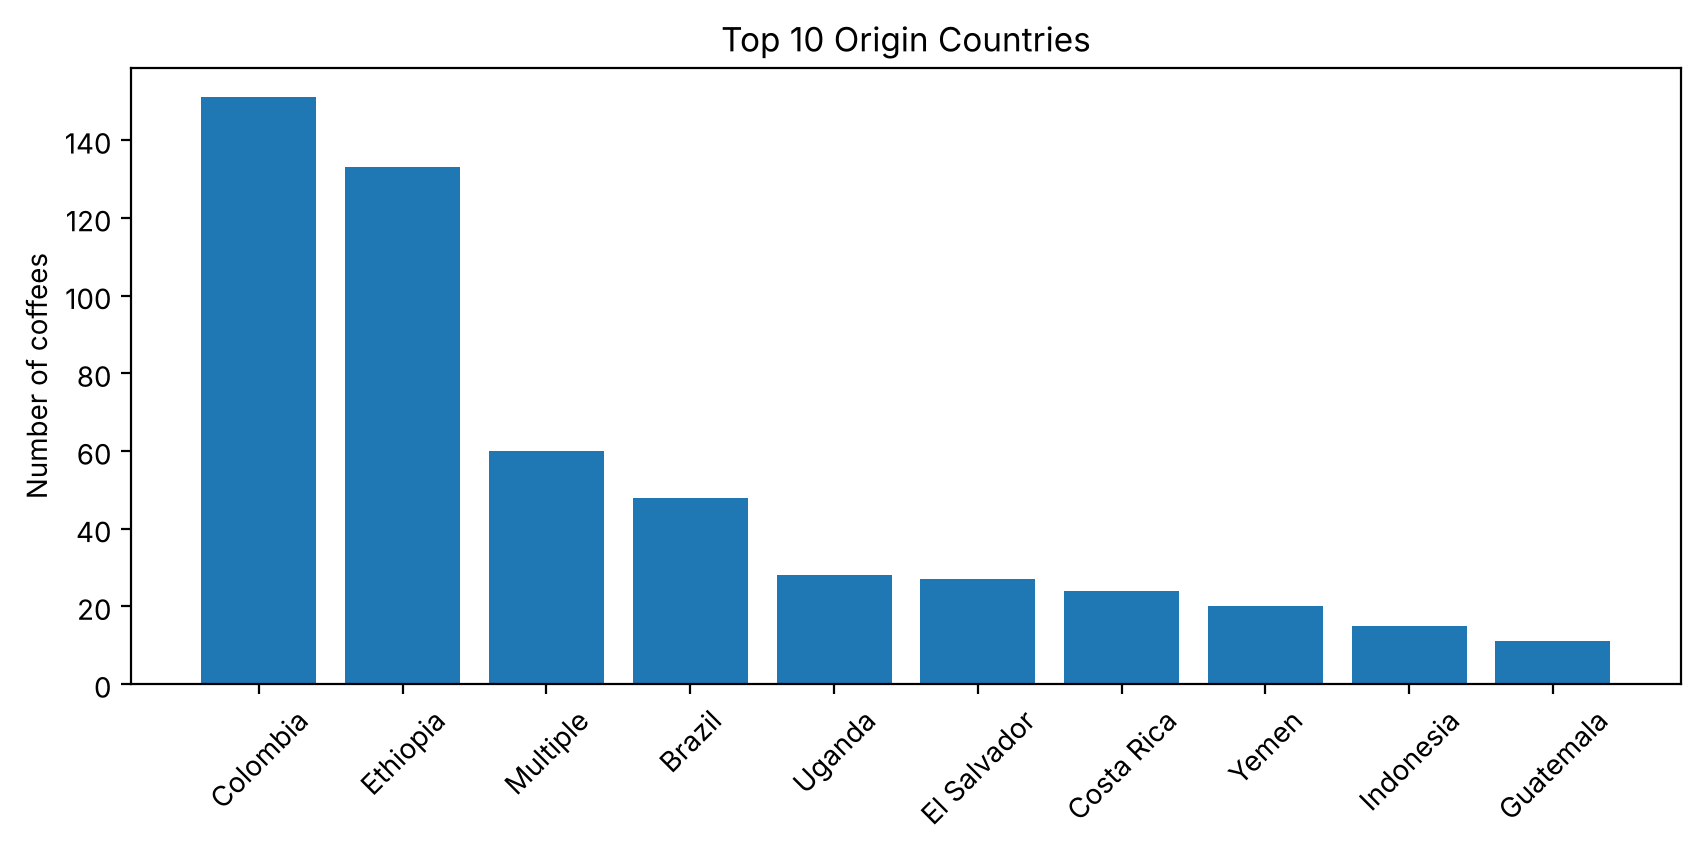

In [ ]:
top_countries = df["origin_country"].value_counts().head(10)

plt.figure(figsize=(10, 4))
plt.bar(top_countries.index, top_countries.values)
plt.xticks(rotation=45)
plt.ylabel("Number of coffees")
plt.title("Top 10 Origin Countries")
plt.show()

Colombia (151) and Ethiopia (133) are by far the most common origins. Multiple (60) comes third because of the blends.

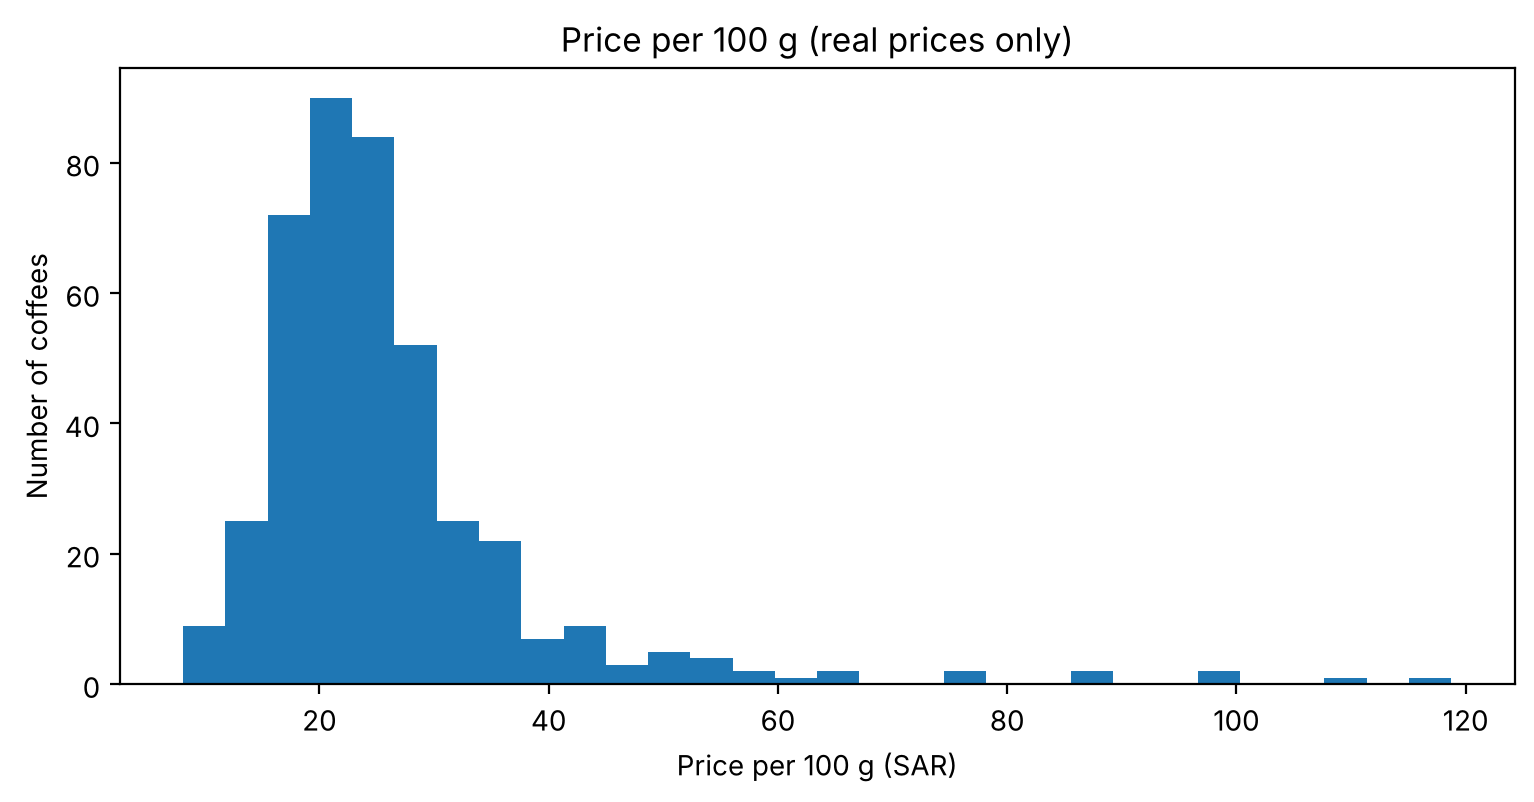

Median price per 100 g: 23.6 SAR


In [ ]:
real = df[df["price_was_filled"] == 0]

plt.figure(figsize=(9, 4))
plt.hist(real["price_per_100g_sar"], bins=30)
plt.xlabel("Price per 100 g (SAR)")
plt.ylabel("Number of coffees")
plt.title("Price per 100 g (real prices only)")
plt.show()

print("Median price per 100 g:", real["price_per_100g_sar"].median(), "SAR")

About 81% of the coffees cost between 15 and 35 SAR per 100 g, and the median is 23.6 SAR. A few special coffees cost much more, up to about 119 SAR per 100 g.

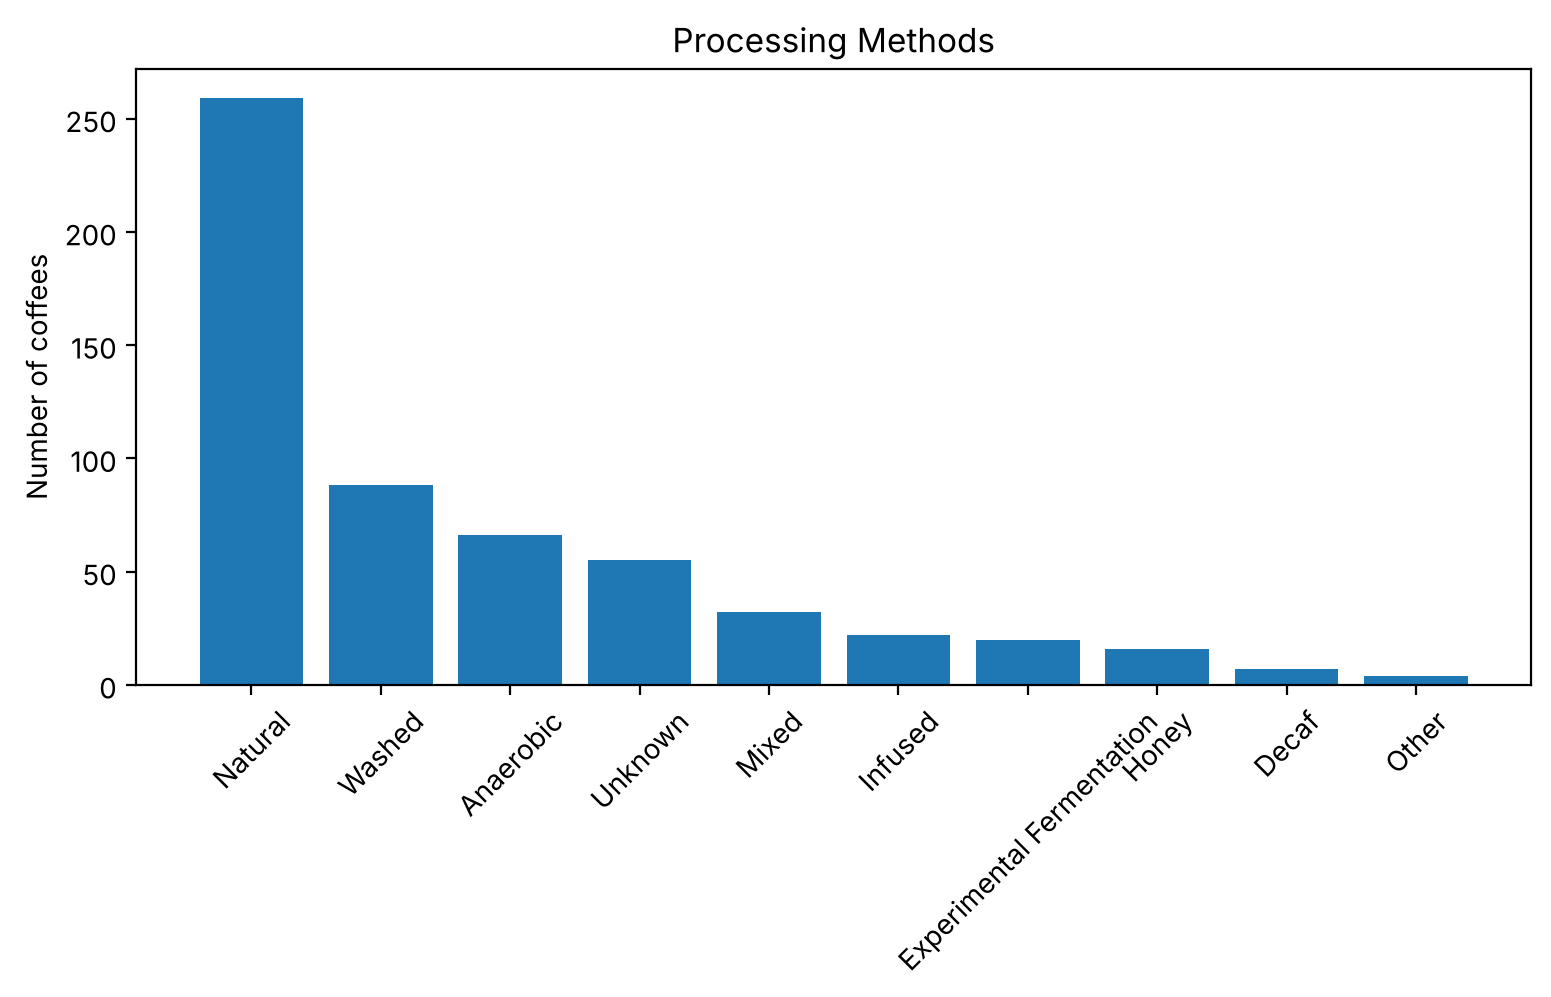

In [ ]:
processes = df["process"].value_counts()

plt.figure(figsize=(9, 4))
plt.bar(processes.index, processes.values)
plt.xticks(rotation=45)
plt.ylabel("Number of coffees")
plt.title("Processing Methods")
plt.show()

**Natural** is the most common process (259 coffees), about three times more than washed (88). Anaerobic and infused coffees are also popular, which shows that Saudi roasters like fruity and experimental coffees. 55 coffees don't state their process.

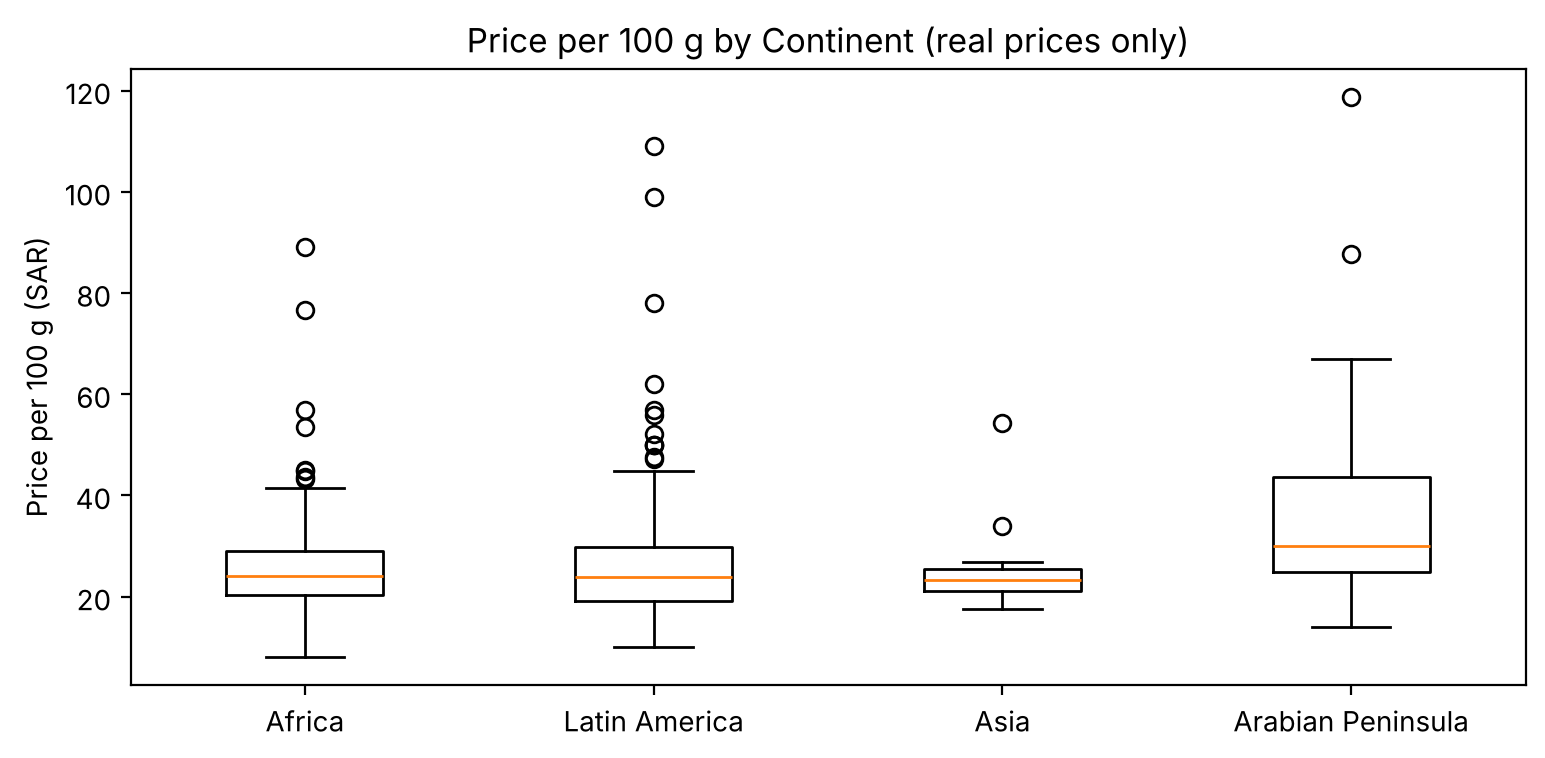

Africa median: 24.0 SAR
Latin America median: 23.92 SAR
Asia median: 23.27 SAR
Arabian Peninsula median: 29.99 SAR


In [ ]:
continents = ["Africa", "Latin America", "Asia", "Arabian Peninsula"]
data = []
for c in continents:
    data.append(real.loc[real["origin_continent"] == c, "price_per_100g_sar"])

plt.figure(figsize=(9, 4))
plt.boxplot(data)
plt.xticks([1, 2, 3, 4], continents)
plt.ylabel("Price per 100 g (SAR)")
plt.title("Price per 100 g by Continent (real prices only)")
plt.show()

for c in continents:
    print(c, "median:", real.loc[real["origin_continent"] == c, "price_per_100g_sar"].median(), "SAR")

Africa, Latin America and Asia have almost the same median price (about 23 to 24 SAR per 100 g), but coffees from the **Arabian Peninsula** (Yemen and Saudi Arabia) are clearly more expensive, with a median of about 30 SAR per 100 g.

## Conclusion

- The dataset has 569 coffees from 71 roasters, with no duplicates.
- **Size:** I filled all 68 missing sizes (46 from the price and 22 from the roaster's usual bag). The rule was right 88.5% of the time on known sizes. The same size was written in up to 12 different ways, and `weight_g` is now the one unified size column.
- **Origin:** I filled all 45 missing origins (39 blends became Multiple, 1 Ethiopia and 5 Unknown), changed the 11 country lists to Multiple, and found 7 regions inside the coffee names.
- **Language:** I translated every Arabic value to English with a translation table of 1,127 entries, and joined values written in different ways. Regions went from 201 to 110 unique values and varieties from 137 to 63.
- **Missing values:** I removed 15 columns that were raw copies, almost empty, or the same in every row. Then I filled the rest: price with the roaster's median price per 100 g, altitude with the country's median, text columns with Unknown, and yes/no columns with 0. The dataset went from 8,672 missing values to **0**.
- **For modeling:** `bean_id`, `coffee_name`, `product_url`, `source_domain` and `other_attributes` are IDs or free text, so I would not use them as features. If I predict the price, I should only train on the rows where `price_was_filled` is 0.

## 19. Save the Clean Dataset

In [ ]:
df.to_csv("saudi_specialty_coffee_beans_clean.csv", index=False, encoding="utf-8-sig")
print("Saved:", df.shape)

Saved: (569, 40)
